# BERT fine-tuning for emotion classification

Fine-tunes `bert-base-uncased` on the 6-class `dair-ai/emotion` dataset. The classes are imbalanced, so macro-F1, precision and recall are reported next to accuracy. To see how much fine-tuning actually buys, the model is compared against four baselines on the same test set: majority class, TF-IDF + logistic regression, a frozen BERT with a linear probe, and zero-shot NLI (`facebook/bart-large-mnli`).

Fine-tuning is repeated over 3 seeds (mean ± std), and the final model is checked with a bootstrap confidence interval, a paired bootstrap of the gain over the best baseline, an exact McNemar test, a per-class report with confusion matrix, and a look at the most confident mistakes. Parameter count and latency are measured at the end.

Run on a Colab T4.

## 1. Setup

In [ ]:
!pip -q install -U transformers datasets accelerate scikit-learn matplotlib seaborn pandas scipy

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.0 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.0 which is incompatible.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


In [ ]:
import os
try:
    from google.colab import userdata
    HF_TOKEN = userdata.get("HF_TOKEN")
except Exception:
    HF_TOKEN = os.environ.get("HF_TOKEN")

if HF_TOKEN:
    from huggingface_hub import login
    login(token=HF_TOKEN, add_to_git_credential=False)

In [ ]:
import os, gc, json, time, random, platform
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt, seaborn as sns
import transformers, datasets
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
OUT_DIR = "/content/bert_out"; os.makedirs(OUT_DIR, exist_ok=True)
print(f"device {DEVICE} ({torch.cuda.get_device_name(0) if DEVICE=='cuda' else 'CPU - training will be slow'}) | torch {torch.__version__} | transformers {transformers.__version__}")

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
def cleanup(): gc.collect(); torch.cuda.empty_cache() if DEVICE == "cuda" else None

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


device cuda (Tesla T4) | torch 2.11.0+cu130 | transformers 5.22.1


## 2. Configuration

In [ ]:
DATASET, TEXT_COL, LABEL_COL = "dair-ai/emotion", "text", "label"
MODEL_NAME = "bert-base-uncased"
MAX_LEN = 128
EPOCHS, LR, BATCH, WARMUP, WD = 3, 2e-5, 32, 0.06, 0.01
SEEDS = [42, 43, 44]            # fine-tuning seeds (mean ± std reported)
RUN_ZEROSHOT = True             # NLI zero-shot baseline (downloads facebook/bart-large-mnli, ~1.6 GB)

## 3. Data and exploratory checks
The label distribution is skewed, which is why macro-F1 is reported alongside accuracy.

README.md:   0%|          | 0.00/9.05k [00:00<?, ?B/s]

split/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

split/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  127kB            

split/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  129kB            

split/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/16000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 16000
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})
labels: ['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']
          train    val   test
label                        
joy       0.335  0.352  0.348
sadness   0.292  0.275  0.290
anger     0.135  0.138  0.138
fear      0.121  0.106  0.112
love      0.082  0.089  0.080
surprise  0.036  0.040  0.033
majority-class share in test: 0.348


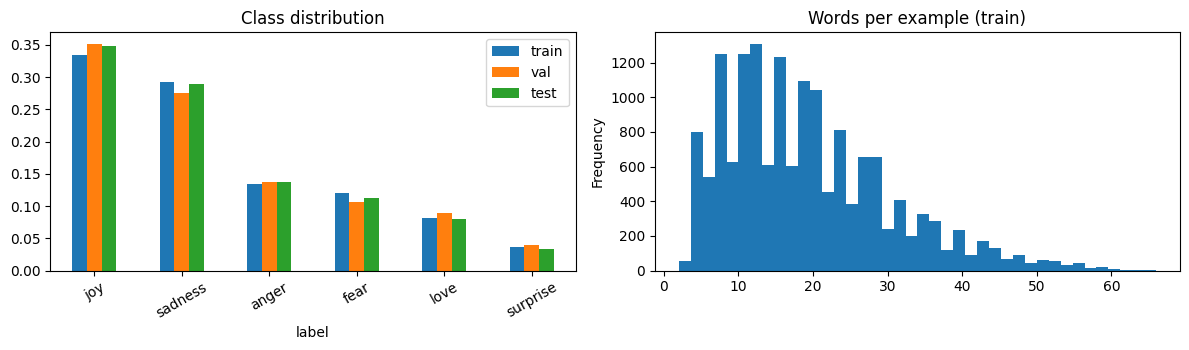

In [ ]:
from datasets import load_dataset
ds = load_dataset(DATASET)
label_names = ds["train"].features[LABEL_COL].names
NUM_LABELS = len(label_names)
print(ds)
print("labels:", label_names)

train_df = ds["train"].to_pandas(); val_df = ds["validation"].to_pandas(); test_df = ds["test"].to_pandas()
dist = pd.DataFrame({s: d[LABEL_COL].map(dict(enumerate(label_names))).value_counts(normalize=True)
                     for s, d in [("train", train_df), ("val", val_df), ("test", test_df)]}).round(3)
print(dist)
print("majority-class share in test:", round(test_df[LABEL_COL].value_counts(normalize=True).max(), 3))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
dist.plot.bar(ax=ax[0]); ax[0].set_title("Class distribution"); ax[0].tick_params(axis="x", rotation=30)
train_df[TEXT_COL].str.split().str.len().plot.hist(bins=40, ax=ax[1]); ax[1].set_title("Words per example (train)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/data_overview.png", dpi=150); plt.show()

## 4. Baselines
All baselines are scored on the same test set with the same metric function.

In [ ]:
leaderboard = []      # one dict per method
PRED = {}             # method -> test predictions (for McNemar / bootstrap)
y_train, y_val, y_test = train_df[LABEL_COL].values, val_df[LABEL_COL].values, test_df[LABEL_COL].values

def score(name, y_true, y_pred, extra=None):
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    row = dict(method=name, accuracy=accuracy_score(y_true, y_pred), precision_macro=p, recall_macro=r, f1_macro=f1,
               f1_weighted=precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)[2])
    if extra: row.update(extra)
    leaderboard.append(row); PRED[name] = np.asarray(y_pred)
    print(f"{name:<42} acc {row['accuracy']:.4f} | macro-F1 {row['f1_macro']:.4f} | P {p:.4f} | R {r:.4f}")
    return row

# 4.1 majority class
maj = int(pd.Series(y_train).mode()[0])
score("Baseline: majority class", y_test, np.full_like(y_test, maj))

# 4.2 TF-IDF + logistic regression (strong classical baseline)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
t0 = time.time()
tfidf = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
                      LogisticRegression(max_iter=3000, C=5.0, class_weight="balanced"))
tfidf.fit(train_df[TEXT_COL], y_train)
score("Baseline: TF-IDF + LogReg", y_test, tfidf.predict(test_df[TEXT_COL]), dict(train_time_s=time.time() - t0))

Baseline: majority class                   acc 0.3475 | macro-F1 0.0860 | P 0.0579 | R 0.1667
Baseline: TF-IDF + LogReg                  acc 0.8820 | macro-F1 0.8370 | P 0.8294 | R 0.8465


{'method': 'Baseline: TF-IDF + LogReg',
 'accuracy': 0.882,
 'precision_macro': 0.829418108183337,
 'recall_macro': 0.8465000765954609,
 'f1_macro': 0.8369704133325078,
 'f1_weighted': 0.8830733807654503,
 'train_time_s': 15.18984341621399}

**4.3 Off-the-shelf BERT (frozen, not fine-tuned) + linear probe** — isolates the benefit of *fine-tuning* vs. just using pre-trained features.

In [ ]:
from transformers import AutoTokenizer, AutoModel
tok = AutoTokenizer.from_pretrained(MODEL_NAME)

@torch.no_grad()
def embed(texts, bs=128):
    enc_model = AutoModel.from_pretrained(MODEL_NAME).to(DEVICE).eval().half() if DEVICE == "cuda" else AutoModel.from_pretrained(MODEL_NAME).eval()
    out = []
    for i in range(0, len(texts), bs):
        b = tok(texts[i:i+bs], padding=True, truncation=True, max_length=MAX_LEN, return_tensors="pt").to(DEVICE)
        h = enc_model(**b).last_hidden_state.float()
        m = b["attention_mask"].unsqueeze(-1).float()
        out.append(((h * m).sum(1) / m.sum(1)).cpu().numpy())       # mean pooling
    del enc_model; cleanup()
    return np.concatenate(out)

t0 = time.time()
Xtr, Xte = embed(train_df[TEXT_COL].tolist()), embed(test_df[TEXT_COL].tolist())
probe = LogisticRegression(max_iter=3000, C=1.0, class_weight="balanced").fit(Xtr, y_train)
score("Baseline: frozen BERT + linear probe", y_test, probe.predict(Xte), dict(train_time_s=time.time() - t0))

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

... (2 outputs left out)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Baseline: frozen BERT + linear probe       acc 0.5895 | macro-F1 0.5297 | P 0.5196 | R 0.5829


{'method': 'Baseline: frozen BERT + linear probe',
 'accuracy': 0.5895,
 'precision_macro': 0.5196438031452909,
 'recall_macro': 0.5829234950283707,
 'f1_macro': 0.5297377440178833,
 'f1_weighted': 0.6074372380566433,
 'train_time_s': 113.68477487564087}

**4.4 Zero-shot** (no task-specific training): NLI model scoring each label as a hypothesis.

In [ ]:
if RUN_ZEROSHOT:
    from transformers import pipeline
    zs = pipeline("zero-shot-classification", model="facebook/bart-large-mnli",
                  device=0 if DEVICE == "cuda" else -1, torch_dtype=torch.float16 if DEVICE == "cuda" else torch.float32)
    t0 = time.time()
    outs = zs(test_df[TEXT_COL].tolist(), candidate_labels=label_names, hypothesis_template="This text expresses {}.", batch_size=32)
    pred_zs = np.array([label_names.index(o["labels"][0]) for o in outs])
    score("Baseline: zero-shot NLI (bart-large-mnli)", y_test, pred_zs, dict(train_time_s=0.0))
    del zs; cleanup()
else:
    print("RUN_ZEROSHOT = False -> skipped")

config.json:   0%|          | 0.00/1.15k [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.63GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Baseline: zero-shot NLI (bart-large-mnli)  acc 0.4655 | macro-F1 0.4327 | P 0.5099 | R 0.4776


## 5. Fine-tune BERT (several seeds)
* `eval_strategy="epoch"` → validation metrics after each epoch (validation curve).
* Model selection uses **validation macro-F1** (`load_best_model_at_end`), the test set is touched **only once per seed** at the end.

In [ ]:
from transformers import (AutoModelForSequenceClassification, TrainingArguments, Trainer, DataCollatorWithPadding)

def tokenize(batch): return tok(batch[TEXT_COL], truncation=True, max_length=MAX_LEN)
enc = ds.map(tokenize, batched=True)
enc = enc.rename_column(LABEL_COL, "labels")
enc.set_format("torch", columns=["input_ids", "attention_mask", "labels"] + (["token_type_ids"] if "token_type_ids" in enc["train"].column_names else []))

def compute_metrics(p):
    logits, labels = p; preds = logits.argmax(-1)
    pr, rc, f1, _ = precision_recall_fscore_support(labels, preds, average="macro", zero_division=0)
    return dict(accuracy=accuracy_score(labels, preds), f1_macro=f1, precision_macro=pr, recall_macro=rc)

histories, seed_rows, seed_logits = {}, [], {}
for seed in SEEDS:
    print("\n" + "=" * 70 + f"\nFine-tuning seed {seed}\n" + "=" * 70)
    seed_all(seed); cleanup()
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=NUM_LABELS, id2label=dict(enumerate(label_names)), label2id={n: i for i, n in enumerate(label_names)})
    args = TrainingArguments(
        output_dir=f"/content/bert_run_{seed}", num_train_epochs=EPOCHS, per_device_train_batch_size=BATCH,
        per_device_eval_batch_size=128, learning_rate=LR, weight_decay=WD, warmup_steps=WARMUP,
        eval_strategy="epoch", save_strategy="epoch", logging_steps=50, load_best_model_at_end=True,
        metric_for_best_model="f1_macro", greater_is_better=True, save_total_limit=1,
        fp16=(DEVICE == "cuda"), seed=seed, report_to="none")
    trainer = Trainer(model=model, args=args, train_dataset=enc["train"], eval_dataset=enc["validation"],
                      data_collator=DataCollatorWithPadding(tok), compute_metrics=compute_metrics)
    t0 = time.time(); trainer.train(); train_s = time.time() - t0
    pred = trainer.predict(enc["test"])
    logits = pred.predictions; yp = logits.argmax(-1)
    name = f"BERT fine-tuned (seed {seed})"
    row = score(name, y_test, yp, dict(train_time_s=train_s))
    seed_rows.append(row); seed_logits[seed] = logits; histories[seed] = trainer.state.log_history
    if seed == SEEDS[0]:
        trainer.save_model(f"{OUT_DIR}/best_model_seed{seed}"); tok.save_pretrained(f"{OUT_DIR}/best_model_seed{seed}")
        n_params = sum(p.numel() for p in trainer.model.parameters())
        best_model_ref = trainer.model
    del trainer, model; cleanup()

Map:   0%|          | 0/16000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]


Fine-tuning seed 42


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


... (20 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

BERT fine-tuned (seed 44)                  acc 0.9255 | macro-F1 0.8862 | P 0.8790 | R 0.8947


## 6. Aggregate over seeds

In [ ]:
sdf = pd.DataFrame(seed_rows)
agg = {m: (sdf[m].mean(), sdf[m].std(ddof=1) if len(sdf) > 1 else 0.0) for m in ["accuracy", "precision_macro", "recall_macro", "f1_macro", "f1_weighted"]}
print(f"Fine-tuned BERT over {len(SEEDS)} seeds:")
for m, (mu, sd) in agg.items(): print(f"  {m:<16} {mu:.4f} ± {sd:.4f}")

# Final leaderboard: baselines + mean±std of fine-tuned runs
lb = pd.DataFrame([r for r in leaderboard if not r["method"].startswith("BERT fine-tuned")])
final = {"method": f"BERT fine-tuned (mean of {len(SEEDS)} seeds)"}
final.update({m: mu for m, (mu, sd) in agg.items()})
final["train_time_s"] = sdf["train_time_s"].mean()
lb = pd.concat([lb, pd.DataFrame([final])], ignore_index=True)
for m, (mu, sd) in agg.items(): lb.loc[lb.index[-1], f"{m}_std"] = sd
lb.to_csv(f"{OUT_DIR}/leaderboard.csv", index=False)

Fine-tuned BERT over 3 seeds:
  accuracy         0.9270 ± 0.0026
  precision_macro  0.8850 ± 0.0079
  recall_macro     0.8849 ± 0.0099
  f1_macro         0.8841 ± 0.0057
  f1_weighted      0.9271 ± 0.0024


## 7. Validation curves (seed 1)

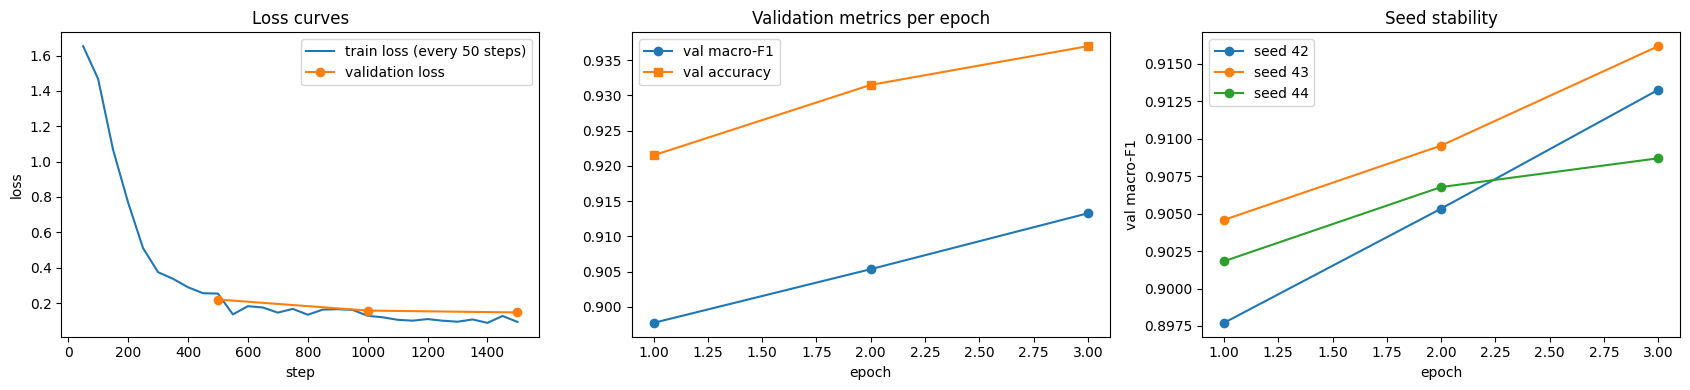

In [ ]:
h = histories[SEEDS[0]]
tr = [(e["step"], e["loss"]) for e in h if "loss" in e and "eval_loss" not in e]
ev = [e for e in h if "eval_loss" in e]
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].plot(*zip(*tr), label="train loss (every 50 steps)")
ax[0].plot([e["step"] for e in ev], [e["eval_loss"] for e in ev], "o-", label="validation loss")
ax[0].set_xlabel("step"); ax[0].set_ylabel("loss"); ax[0].legend(); ax[0].set_title("Loss curves")
ax[1].plot([e["epoch"] for e in ev], [e["eval_f1_macro"] for e in ev], "o-", label="val macro-F1")
ax[1].plot([e["epoch"] for e in ev], [e["eval_accuracy"] for e in ev], "s-", label="val accuracy")
ax[1].set_xlabel("epoch"); ax[1].legend(); ax[1].set_title("Validation metrics per epoch")
for s in SEEDS:
    e_ = [e for e in histories[s] if "eval_f1_macro" in e]
    ax[2].plot([e["epoch"] for e in e_], [e["eval_f1_macro"] for e in e_], "o-", label=f"seed {s}")
ax[2].set_xlabel("epoch"); ax[2].set_ylabel("val macro-F1"); ax[2].legend(); ax[2].set_title("Seed stability")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/validation_curves.png", dpi=160); plt.show()

## 8. Final comparison (baseline → fine-tuned)

,method,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,train_time_s
0,Baseline: majority class,0.3475,0.0579,0.1667,0.0860,0.1792,NaN
1,Baseline: TF-IDF + LogReg,0.8820,0.8294,0.8465,0.8370,0.8831,15.1898
2,Baseline: frozen BERT + linear probe,0.5895,0.5196,0.5829,0.5297,0.6074,113.6848
3,Baseline: zero-shot NLI (bart-large-mnli),0.4655,0.5099,0.4776,0.4327,0.5237,0.0000
4,BERT fine-tuned (mean of 3 seeds),0.9270,0.8850,0.8849,0.8841,0.9271,290.7637


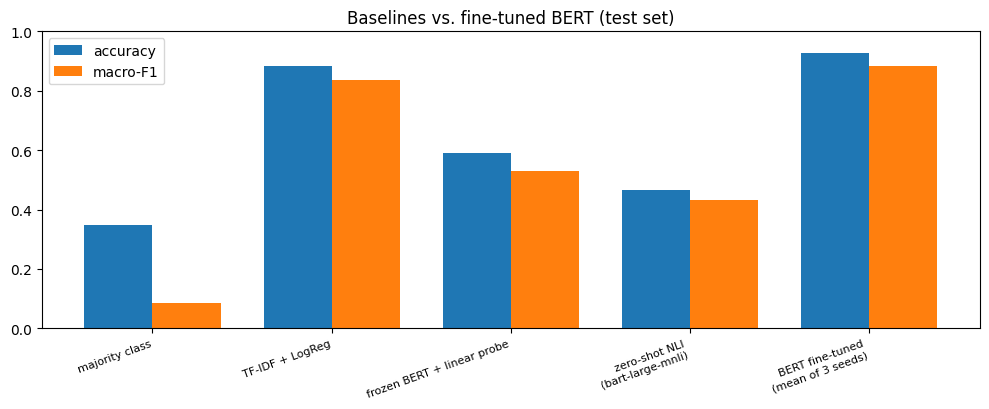

In [ ]:
pd.set_option("display.width", 220)
show = lb[["method", "accuracy", "precision_macro", "recall_macro", "f1_macro", "f1_weighted", "train_time_s"]].copy()
display(show.round(4))

fig, ax = plt.subplots(figsize=(10, 4.2))
x = np.arange(len(lb)); w = 0.38
ax.bar(x - w/2, lb.accuracy, w, label="accuracy"); ax.bar(x + w/2, lb.f1_macro, w, label="macro-F1")
ax.set_xticks(x); ax.set_xticklabels([m.replace("Baseline: ", "").replace(" (", "\n(") for m in lb.method], rotation=20, ha="right", fontsize=8)
ax.set_ylim(0, 1); ax.legend(); ax.set_title("Baselines vs. fine-tuned BERT (test set)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/comparison.png", dpi=160); plt.show()

## 9. Statistical checks and error analysis (seed 1 model)
* **Bootstrap 95 % CI** of macro-F1 on the test set.
* **Paired bootstrap** of the macro-F1 gain over the strongest baseline, and an **exact McNemar test** on per-example correctness.

In [ ]:
from scipy.stats import binomtest
rng = np.random.default_rng(0)
ft_name = f"BERT fine-tuned (seed {SEEDS[0]})"
base_names = [m for m in PRED if m.startswith("Baseline:") and "majority" not in m]
def f1m(y, p): return precision_recall_fscore_support(y, p, average="macro", zero_division=0)[2]
best_base = max(base_names, key=lambda m: f1m(y_test, PRED[m]))
print("Strongest non-trivial baseline:", best_base)

n = len(y_test); B = 1000
fts, gains = [], []
for _ in range(B):
    idx = rng.integers(0, n, n)
    a, b_ = f1m(y_test[idx], PRED[ft_name][idx]), f1m(y_test[idx], PRED[best_base][idx])
    fts.append(a); gains.append(a - b_)
print(f"Fine-tuned macro-F1 95% CI: [{np.percentile(fts, 2.5):.4f}, {np.percentile(fts, 97.5):.4f}]")
print(f"Gain over {best_base}: {np.mean(gains):+.4f} (95% CI [{np.percentile(gains, 2.5):+.4f}, {np.percentile(gains, 97.5):+.4f}])")

ca, cb = PRED[ft_name] == y_test, PRED[best_base] == y_test
n01, n10 = int((~ca & cb).sum()), int((ca & ~cb).sum())           # only baseline right / only fine-tuned right
pval = binomtest(min(n01, n10), n01 + n10, 0.5).pvalue if (n01 + n10) else 1.0
print(f"McNemar (exact): fine-tuned-only correct={n10}, baseline-only correct={n01}, p={pval:.2e}")

Strongest non-trivial baseline: Baseline: TF-IDF + LogReg
Fine-tuned macro-F1 95% CI: [0.8663, 0.9079]
Gain over Baseline: TF-IDF + LogReg: +0.0517 (95% CI [+0.0268, +0.0765])
McNemar (exact): fine-tuned-only correct=155, baseline-only correct=59, p=3.94e-11


              precision    recall  f1-score   support

     sadness     0.9638    0.9621    0.9630       581
         joy     0.9606    0.9468    0.9536       695
        love     0.8344    0.8553    0.8447       159
       anger     0.9197    0.9164    0.9180       275
        fear     0.8636    0.9330    0.8970       224
    surprise     0.8214    0.6970    0.7541        66

    accuracy                         0.9300      2000
   macro avg     0.8939    0.8851    0.8884      2000
weighted avg     0.9304    0.9300    0.9299      2000



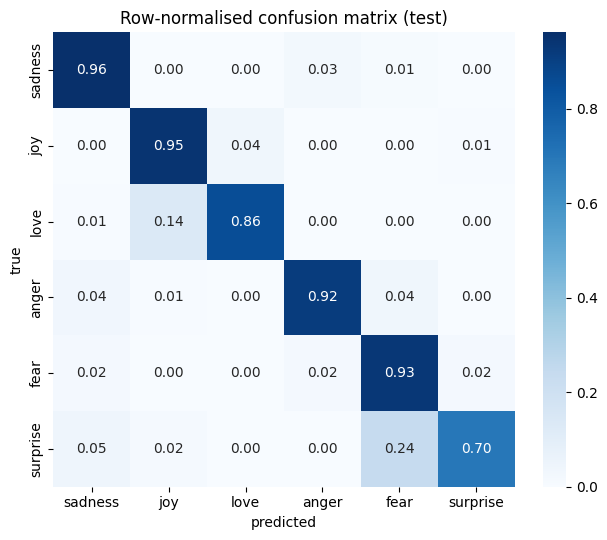

,text,true,pred,confidence
0,i cannot even begin to express in words the de...,surprise,sadness,0.997
1,whenever i put myself in others shoes and try ...,anger,joy,0.997
2,i feel betrayed and angry and sad at the same ...,anger,sadness,0.997
3,i don t feel betrayed coz the backstabber had ...,surprise,sadness,0.997
4,i walked to school he felt the bounce in his s...,love,joy,0.996
5,i feel inside cause life is like a game someti...,fear,sadness,0.995
6,i just feel are ludicrous and wasting space or...,surprise,sadness,0.992
7,i was playing a sport in an advanced pe class ...,anger,joy,0.990
8,i feel i can only hope im not alone in these t...,sadness,joy,0.984
9,i dont want to always be judgmental of particu...,sadness,anger,0.982


In [ ]:
yp = PRED[ft_name]
print(classification_report(y_test, yp, target_names=label_names, digits=4))
cm = confusion_matrix(y_test, yp, normalize="true")
plt.figure(figsize=(6.5, 5.5))
sns.heatmap(cm, annot=True, fmt=".2f", xticklabels=label_names, yticklabels=label_names, cmap="Blues")
plt.xlabel("predicted"); plt.ylabel("true"); plt.title("Row-normalised confusion matrix (test)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/confusion_matrix.png", dpi=160); plt.show()

# Most confident mistakes
probs = torch.softmax(torch.tensor(seed_logits[SEEDS[0]]), -1).numpy()
err = np.where(yp != y_test)[0]
err = err[np.argsort(-probs[err].max(1))][:10]
pd.DataFrame({"text": test_df[TEXT_COL].values[err], "true": [label_names[i] for i in y_test[err]],
              "pred": [label_names[i] for i in yp[err]], "confidence": probs[err].max(1).round(3)})

## 10. Efficiency

In [ ]:
m = best_model_ref.eval().to(DEVICE)
batch = tok(test_df[TEXT_COL].tolist()[:32], padding="max_length", truncation=True, max_length=MAX_LEN, return_tensors="pt").to(DEVICE)
one = {k: v[:1] for k, v in batch.items()}
@torch.no_grad()
def lat(inp, reps=30):
    for _ in range(5): m(**inp)
    if DEVICE == "cuda": torch.cuda.synchronize()
    t = time.perf_counter()
    for _ in range(reps): m(**inp)
    if DEVICE == "cuda": torch.cuda.synchronize()
    return (time.perf_counter() - t) / reps * 1000
eff = dict(parameters_M=n_params / 1e6, size_fp32_MB=n_params * 4 / 1024**2,
           latency_ms_batch1=lat(one), latency_ms_batch32=lat(batch), device=DEVICE)
eff["throughput_examples_per_s_batch32"] = 32 / (eff["latency_ms_batch32"] / 1000)
print(json.dumps(eff, indent=2)); json.dump(eff, open(f"{OUT_DIR}/efficiency.json", "w"), indent=2)

{
  "parameters_M": 109.486854,
  "size_fp32_MB": 417.6592025756836,
  "latency_ms_batch1": 13.11157946666602,
  "latency_ms_batch32": 56.63122893333821,
  "device": "cuda",
  "throughput_examples_per_s_batch32": 565.0592544560152
}


## 11. Findings

* **Fine-tuned BERT** reaches 0.927 ± 0.003 accuracy and 0.884 ± 0.006 macro-F1 on the test set (mean ± std over 3 seeds).
* **Baselines** (accuracy / macro-F1): majority class 0.347 / 0.086, TF-IDF + LogReg 0.882 / 0.837, frozen BERT + linear probe 0.590 / 0.530, zero-shot NLI 0.466 / 0.433. TF-IDF + LogReg is by far the strongest of these, and frozen BERT features with a linear probe do much worse, so on this task the gain comes from fine-tuning rather than from the pre-trained representation alone.
* **Significance.** Seed 1 beats TF-IDF + LogReg by +0.052 macro-F1 (paired bootstrap 95% CI [+0.027, +0.077]); the exact McNemar test gives p = 3.9e-11 (155 examples only the fine-tuned model got right vs. 59 only the baseline got right).
* **Per class** (seed 1), the weak spots are *surprise* (F1 0.75, recall 0.70, only 66 test examples) and *love* (F1 0.84). *sadness* and *joy* are both above 0.95.
* **Mistakes.** The most confident errors are often questionable labels or genuinely mixed emotions (e.g. "i feel betrayed and angry and sad at the same time" labelled anger, predicted sadness). The dataset's labels come from hashtags, so some of the remaining error is label noise rather than model error.
* **Cost.** 109M parameters (418 MB in FP32), 13.1 ms per example at batch size 1 and ~565 examples/s at batch 32 on the GPU.

Limitations: three seeds on a single train/validation/test split, no hyperparameter search (3 epochs, lr 2e-5), and results only apply to this dataset.

In [ ]:
# ---- Zip everything and download ------------------------------------------
import shutil
shutil.make_archive("/content/bert_results", "zip", OUT_DIR)
try:
    from google.colab import files
    files.download("/content/bert_results.zip")
except Exception as e:
    print("Not in Colab (or download blocked). Results are in", OUT_DIR, "->", e)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>